# Elastic Net: Cyclical sector volatility forecasting (expanding window)
Cyclical bucket: **XLI, XLB, XLE, XLY, XLF** 

Sample: **January 1999 – December 2025** 

## 1.Macro variable selection

Select macro variables using **only the first 60 months** of data (matching our
walk-forward initial training window: Jan 1999 – Dec 2003)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.stattools import adfuller

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

PROJECT_ROOT = "../.."  # scripts/elastic_net -> project root
ETF_PRICES_PATH = os.path.join(PROJECT_ROOT, "dataset", "sector_etf_prices.csv")

CYCLICAL_TICKERS = ["XLI", "XLB", "XLE", "XLY", "XLF"] 
FRED_CSV_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"

CANDIDATE_SERIES = {
    "T10Y2Y": ("rates_yield_curve", "daily", 0),
    "DGS3MO": ("rates_yield_curve", "daily", 0),
    "BAMLH0A0HYM2": ("credit_spreads", "daily", 0),
    "BAA10Y": ("credit_spreads", "daily", 0),
    "CPIAUCSL": ("inflation", "monthly", 1),
    "PCEPI": ("inflation", "monthly", 1),
    "T5YIE": ("inflation", "daily", 0),
    "T10YIE": ("inflation", "daily", 0),
    "M2SL": ("inflation", "monthly", 1),
    "VIXCLS": ("volatility_stress", "daily", 0),
    "NFCI": ("volatility_stress", "weekly", 0),
    "STLFSI4": ("volatility_stress", "weekly", 0),
    "INDPRO": ("real_activity_labour", "monthly", 1),
    "CFNAI": ("real_activity_labour", "monthly", 1),
    "UNRATE": ("real_activity_labour", "monthly", 1),
    "ICSA": ("real_activity_labour", "weekly", 0),
    "UMCSENT": ("real_activity_labour", "monthly", 0),
    "DTWEXBGS": ("dollar_commodity", "daily", 0),
    "DCOILWTICO": ("dollar_commodity", "daily", 0),
}

def fetch_fred_series(series_id):
    df = pd.read_csv(FRED_CSV_URL.format(series_id=series_id), parse_dates=["observation_date"])
    df = df.set_index("observation_date")
    df.index.name = "date"
    return df[series_id]

In [2]:
SAMPLE_START = "1999-01-01"
INITIAL_TRAIN_MONTHS = 60  

macro_data = {}
for series_id, (channel, freq, lag_months) in CANDIDATE_SERIES.items():
    raw = fetch_fred_series(series_id)
    monthly = raw.resample("ME").mean().shift(lag_months)
    macro_data[series_id] = monthly
    print(f"fetched {series_id:14s} raw range {raw.index.min().date()} to {raw.index.max().date()}")

macro = pd.DataFrame(macro_data).sort_index()
macro_sample = macro[macro.index >= SAMPLE_START]
first_window = macro_sample.iloc[:INITIAL_TRAIN_MONTHS]

print()
print("Full usable macro sample:", macro_sample.index[0].date(), "to", macro_sample.index[-1].date(),
      f"({len(macro_sample)} months)")
print("First-60-months window used for variable selection:",
      first_window.index[0].date(), "to", first_window.index[-1].date())
first_window.head()

fetched T10Y2Y         raw range 1976-06-01 to 2026-09-04
fetched DGS3MO         raw range 1981-09-01 to 2026-09-03
fetched BAMLH0A0HYM2   raw range 2023-09-05 to 2026-09-03
fetched BAA10Y         raw range 1986-01-02 to 2026-09-03
fetched CPIAUCSL       raw range 1947-01-01 to 2026-07-01
fetched PCEPI          raw range 1959-01-01 to 2026-07-01
fetched T5YIE          raw range 2003-01-02 to 2026-09-04
fetched T10YIE         raw range 2003-01-02 to 2026-09-04
fetched M2SL           raw range 1959-01-01 to 2026-07-01
fetched VIXCLS         raw range 1990-01-02 to 2026-09-03
fetched NFCI           raw range 1971-01-08 to 2026-08-28
fetched STLFSI4        raw range 1993-12-31 to 2026-08-28
fetched INDPRO         raw range 1919-01-01 to 2026-07-01
fetched CFNAI          raw range 1967-03-01 to 2026-07-01
fetched UNRATE         raw range 1948-01-01 to 2026-08-01
fetched ICSA           raw range 1967-01-07 to 2026-08-29
fetched UMCSENT        raw range 1952-11-01 to 2026-07-01
fetched DTWEXB

,T10Y2Y,DGS3MO,BAMLH0A0HYM2,BAA10Y,CPIAUCSL,PCEPI,T5YIE,T10YIE,M2SL,VIXCLS,NFCI,STLFSI4,INDPRO,CFNAI,UNRATE,ICSA,UMCSENT,DTWEXBGS,DCOILWTICO
date,,,,,,,,,,,,,,,,,,,
1999-01-31,0.106842,4.446316,NaN,2.565789,164.4,71.298,NaN,NaN,4375.5,28.035263,-0.2342,0.364720,87.1185,0.25,4.4,326200.0,103.9,NaN,12.514737
1999-02-28,0.122632,4.555263,NaN,2.390000,164.7,71.398,NaN,NaN,4401.7,28.822632,-0.3205,0.147225,87.4949,0.11,4.3,301500.0,108.1,NaN,12.013684
1999-03-31,0.179565,4.566522,NaN,2.301304,164.7,71.358,NaN,NaN,4423.7,25.309565,-0.3865,0.106975,88.0270,0.54,4.4,302750.0,105.7,NaN,14.676522
1999-04-30,0.207727,4.409091,NaN,2.294545,164.8,71.412,NaN,NaN,4430.1,23.478571,-0.4170,0.042160,88.2267,-0.08,4.2,308500.0,104.6,NaN,17.312381
1999-05-31,0.285000,4.631000,NaN,2.182500,165.9,71.757,NaN,NaN,4459.9,26.204500,-0.4125,0.149200,88.4295,0.00,4.3,301600.0,106.8,NaN,17.718500


In [3]:
# check for missing data
FULL_SAMPLE_END = "2025-12-31"
full_sample = macro[(macro.index >= SAMPLE_START) & (macro.index <= FULL_SAMPLE_END)]
print("Full working sample:", full_sample.index[0].date(), "to", full_sample.index[-1].date(),
      f"({len(full_sample)} months)\n")

print("Missing months, full working sample")
print(full_sample.isnull().sum().sort_values(ascending=False))

print()
print("Missing months, first-60-months window only (Jan 1999 - Dec 2003)")
print(first_window.isnull().sum().sort_values(ascending=False))

Full working sample: 1999-01-31 to 2025-12-31 (324 months)

Missing months, full working sample
BAMLH0A0HYM2    296
DTWEXBGS         84
T5YIE            48
T10YIE           48
CPIAUCSL          1
UNRATE            1
T10Y2Y            0
INDPRO            0
UMCSENT           0
ICSA              0
CFNAI             0
VIXCLS            0
STLFSI4           0
NFCI              0
DGS3MO            0
M2SL              0
PCEPI             0
BAA10Y            0
DCOILWTICO        0
dtype: int64

Missing months, first-60-months window only (Jan 1999 - Dec 2003)
BAMLH0A0HYM2    60
DTWEXBGS        60
T5YIE           48
T10YIE          48
T10Y2Y           0
STLFSI4          0
UMCSENT          0
ICSA             0
UNRATE           0
CFNAI            0
INDPRO           0
VIXCLS           0
NFCI             0
DGS3MO           0
M2SL             0
PCEPI            0
CPIAUCSL         0
BAA10Y           0
DCOILWTICO       0
dtype: int64


In [4]:
CANDIDATE_CHANNELS = {
    "rates_yield_curve": ["T10Y2Y", "DGS3MO"],
    "credit_spreads": ["BAA10Y"],
    "inflation": ["CPIAUCSL", "PCEPI", "M2SL"],
    "volatility_stress": ["VIXCLS", "NFCI", "STLFSI4"],
    "real_activity_labour": ["INDPRO", "CFNAI", "UNRATE", "ICSA", "UMCSENT"],
    "dollar_commodity": ["DCOILWTICO"],
}

REDUNDANCY_THRESHOLD = 0.8  # |corr| above this is considered redundant
for channel, cols in CANDIDATE_CHANNELS.items():
    corr = first_window[cols].corr().round(3)
    n_missing = first_window[cols].isnull().sum()
    print(f"=== {channel} ===")
    print(corr)
    if n_missing.any():
        print("missing months in this window:", n_missing[n_missing > 0].to_dict())
    # flag any pair above the redundancy threshold
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            v = corr.iloc[i, j]
            if pd.notna(v) and abs(v) > REDUNDANCY_THRESHOLD:
                print(f"  REDUNDANT PAIR: {cols[i]} vs {cols[j]} = {v}")
    print()

=== rates_yield_curve ===
        T10Y2Y  DGS3MO
T10Y2Y   1.000  -0.987
DGS3MO  -0.987   1.000
  REDUNDANT PAIR: T10Y2Y vs DGS3MO = -0.987

=== credit_spreads ===
        BAA10Y
BAA10Y     1.0

=== inflation ===
          CPIAUCSL  PCEPI   M2SL
CPIAUCSL     1.000  0.998  0.978
PCEPI        0.998  1.000  0.981
M2SL         0.978  0.981  1.000
  REDUNDANT PAIR: CPIAUCSL vs PCEPI = 0.998
  REDUNDANT PAIR: CPIAUCSL vs M2SL = 0.978
  REDUNDANT PAIR: PCEPI vs M2SL = 0.981

=== volatility_stress ===
         VIXCLS   NFCI  STLFSI4
VIXCLS    1.000  0.202    0.828
NFCI      0.202  1.000    0.032
STLFSI4   0.828  0.032    1.000
  REDUNDANT PAIR: VIXCLS vs STLFSI4 = 0.828

=== real_activity_labour ===
         INDPRO  CFNAI  UNRATE   ICSA  UMCSENT
INDPRO    1.000  0.048  -0.198 -0.234    0.123
CFNAI     0.048  1.000  -0.040 -0.512    0.457
UNRATE   -0.198 -0.040   1.000  0.755   -0.753
ICSA     -0.234 -0.512   0.755  1.000   -0.912
UMCSENT   0.123  0.457  -0.753 -0.912    1.000
  REDUNDANT PAIR: 

## Macro Variable Selection: Final Set (based on Jan 1999–Dec 2003 correlation check)

Within each channel, we drop a variable if it correlates ≥ 0.8 with another variable in the same channel.

#### Rates / yield curve
- **Kept: T10Y2Y**
- **Dropped: DGS3MO** (corr = -0.987)

#### Credit spreads
- **Kept: BAA10Y** 

### Inflation
- **Kept: PCEPI**
- **Dropped: CPIAUCSL, M2SL** 
Kept PCEPI since it represents inflation the best
### Volatility / financial stress
- **Kept: VIXCLS, NFCI**
- **Dropped: STLFSI4** 

### Real activity / labour markets
- **Kept: INDPRO, CFNAI, UNRATE, ICSA**
- **Dropped: UMCSENT** 

### Dollar / commodity exposure
- **Kept: DCOILWTICO**

### Final variable set (10 variables across 6 channels)
T10Y2Y, BAA10Y, PCEPI, VIXCLS, NFCI, INDPRO, CFNAI, UNRATE, ICSA, DCOILWTICO

In [5]:
FINAL_MACRO_VARS = [
    "T10Y2Y",                              # rates_yield_curve
    "BAA10Y",                              # credit_spreads
    "PCEPI",                               # inflation
    "VIXCLS", "NFCI",                      # volatility_stress
    "INDPRO", "CFNAI", "UNRATE", "ICSA",   # real_activity_labour
    "DCOILWTICO",                          # dollar_commodity
]
print(f"{len(FINAL_MACRO_VARS)} variables:", FINAL_MACRO_VARS)

10 variables: ['T10Y2Y', 'BAA10Y', 'PCEPI', 'VIXCLS', 'NFCI', 'INDPRO', 'CFNAI', 'UNRATE', 'ICSA', 'DCOILWTICO']


## 2. Stationarity check (ADF, first 60 months window)


In [6]:
adf_results = []
for var in FINAL_MACRO_VARS:
    series = first_window[var].dropna()
    stat, pval, *_ = adfuller(series, autolag="AIC", result_object=False)
    adf_results.append({
        "variable": var,
        "adf_stat": round(stat, 3),
        "p_value": round(pval, 4),
        "verdict": "stationary (keep levels)" if pval < 0.05 else "non-stationary (transform)",
    })

adf_df = pd.DataFrame(adf_results).set_index("variable")
adf_df

,adf_stat,p_value,verdict
variable,,,
T10Y2Y,-0.484,0.8952,non-stationary (transform)
BAA10Y,-1.921,0.3224,non-stationary (transform)
PCEPI,-0.506,0.8908,non-stationary (transform)
VIXCLS,-3.508,0.0078,stationary (keep levels)
NFCI,-0.519,0.8882,non-stationary (transform)
INDPRO,-2.624,0.0881,non-stationary (transform)
CFNAI,-1.956,0.3064,non-stationary (transform)
UNRATE,-0.265,0.9304,non-stationary (transform)
ICSA,-1.902,0.3310,non-stationary (transform)


## 2b. Apply transformations

In [7]:
VAR_TRANSFORMS = {
    "VIXCLS": "level",
    "T10Y2Y": "diff1",
    "BAA10Y": "diff1",
    "NFCI": "diff1",
    "CFNAI": "diff1",
    "UNRATE": "diff1",
    "PCEPI": "log_change1",
    "INDPRO": "log_change1",
    "ICSA": "log_change1",
    "DCOILWTICO": "log_change1",
}
assert set(VAR_TRANSFORMS) == set(FINAL_MACRO_VARS), "VAR_TRANSFORMS must cover exactly FINAL_MACRO_VARS"

def apply_transform(series, kind):
    if kind == "level":
        return series
    elif kind == "diff1":
        return series.diff(1)
    elif kind == "log_change1":
        return np.log(series).diff(1)
    else:
        raise ValueError(f"unknown transform kind: {kind}")

macro_filled = macro.copy()
n_before = macro_filled["UNRATE"].isnull().sum()
macro_filled["UNRATE"] = macro_filled["UNRATE"].ffill(limit=1)
n_after = macro_filled["UNRATE"].isnull().sum()
print(f"UNRATE missing (full history): {n_before} before ffill -> {n_after} after ffill(limit=1)")

macro_transformed_full = pd.DataFrame(index=macro_filled.index)
for var, kind in VAR_TRANSFORMS.items():
    macro_transformed_full[var] = apply_transform(macro_filled[var], kind)

macro_transformed = macro_transformed_full[macro_transformed_full.index >= SAMPLE_START]
print(f"macro_transformed: {macro_transformed.index.min().date()} to {macro_transformed.index.max().date()}, "
      f"{macro_transformed.shape[0]} rows, {macro_transformed.iloc[0].isnull().sum()} nulls in first row "
      "(should be 0, confirming the fix)")
macro_transformed.head(3)

UNRATE missing (full history): 351 before ffill -> 349 after ffill(limit=1)
macro_transformed: 1999-01-31 to 2026-09-30, 333 rows, 0 nulls in first row (should be 0, confirming the fix)


,VIXCLS,T10Y2Y,BAA10Y,NFCI,CFNAI,UNRATE,PCEPI,INDPRO,ICSA,DCOILWTICO
date,,,,,,,,,,
1999-01-31,28.035263,-0.031794,-0.015574,-0.07695,0.20,0.0,0.001010,0.004520,0.031768,0.097929
1999-02-28,28.822632,0.015789,-0.175789,-0.08630,-0.14,-0.1,0.001402,0.004311,-0.078741,-0.040861
1999-03-31,25.309565,0.056934,-0.088696,-0.06600,0.43,0.1,-0.000560,0.006063,0.004137,0.200203


## 2c. Re-run ADF on the transformed series


In [8]:
first_window_transformed = macro_transformed[macro_transformed.index >= SAMPLE_START].iloc[:INITIAL_TRAIN_MONTHS]

adf_results_transformed = []
for var in FINAL_MACRO_VARS:
    series = first_window_transformed[var].dropna()
    stat, pval, *_ = adfuller(series, autolag="AIC", result_object=False)
    adf_results_transformed.append({
        "variable": var,
        "transform": VAR_TRANSFORMS[var],
        "adf_stat": round(stat, 3),
        "p_value": round(pval, 4),
        "verdict": "stationary" if pval < 0.05 else "STILL NON-STATIONARY",
    })

adf_transformed_df = pd.DataFrame(adf_results_transformed).set_index("variable")
adf_transformed_df

,transform,adf_stat,p_value,verdict
variable,,,,
T10Y2Y,diff1,-2.649,0.0834,STILL NON-STATIONARY
BAA10Y,diff1,-5.114,0.0000,stationary
PCEPI,log_change1,-6.943,0.0000,stationary
VIXCLS,level,-3.508,0.0078,stationary
NFCI,diff1,-3.908,0.0020,stationary
INDPRO,log_change1,-2.953,0.0396,stationary
CFNAI,diff1,-10.602,0.0000,stationary
UNRATE,diff1,-7.099,0.0000,stationary
ICSA,log_change1,-1.468,0.5494,STILL NON-STATIONARY


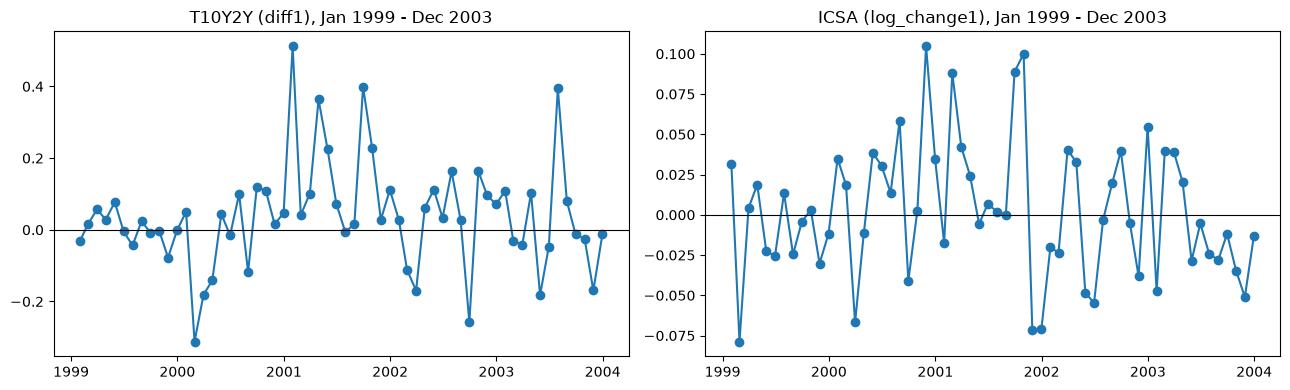

In [9]:
# plot non-stationary transformed variables
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, var in zip(axes, ["T10Y2Y", "ICSA"]):
    series = first_window_transformed[var]
    ax.plot(series.index, series.values, marker="o")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{var} ({VAR_TRANSFORMS[var]}), Jan 1999 - Dec 2003")
fig.tight_layout()
plt.show()

### Note on T10Y2Y and ICSA: still non-stationary after transformation

Both variables remain non-stationary by ADF after their transformations, even in this first-60-month window
(Jan 1999–Dec 2003). 
We retain the transformed variable for both variables
rather than applying further transformation, since additional differencing
would distort economically meaningful variation.

## 3. Target construction — monthly log(RV²) per cyclical ETF, using CRSP

In [10]:
CRSP_PATH = os.path.join(PROJECT_ROOT, "dataset", "sector_etf_prices_crsp.csv")

crsp = pd.read_csv(CRSP_PATH, parse_dates=["DlyCalDt"])
crsp = crsp[crsp["Ticker"].isin(CYCLICAL_TICKERS)]

print("Tickers found:", sorted(crsp["Ticker"].unique()))
print("Date range:", crsp["DlyCalDt"].min().date(), "to", crsp["DlyCalDt"].max().date())
print("Nulls in DlyRet:", crsp["DlyRet"].isnull().sum())

# Wide matrix: date x ticker, daily dividend-adjusted returns
daily_returns = crsp.pivot(index="DlyCalDt", columns="Ticker", values="DlyRet").sort_index()
daily_returns.index.name = "date"
print()
print("daily_returns shape:", daily_returns.shape)
daily_returns.head()

Tickers found: ['XLB', 'XLE', 'XLF', 'XLI', 'XLY']
Date range: 1999-01-04 to 2025-12-31
Nulls in DlyRet: 0

daily_returns shape: (6791, 5)


Ticker,XLB,XLE,XLF,XLI,XLY
date,,,,,
1999-01-04,-0.012117,-0.000669,0.000000,-0.013995,-0.005981
1999-01-05,0.024531,-0.005358,0.009333,0.020645,0.016847
1999-01-06,0.017606,0.032997,0.031704,0.021492,0.028402
1999-01-07,-0.007612,-0.004563,0.015365,-0.008663,-0.001151
1999-01-08,0.034170,0.004584,0.006305,0.007491,0.001152


In [11]:
# Monthly RV^2 (realized variance) per ticker: sum of squared daily returns within each month
monthly_rv_squared = daily_returns.pow(2).resample("ME").sum()
log_rv_squared = np.log(monthly_rv_squared)

print("monthly_rv_squared shape:", monthly_rv_squared.shape)
print("date range:", monthly_rv_squared.index.min().date(), "to", monthly_rv_squared.index.max().date())
print()
print("--- monthly RV², first 5 months ---")
print(monthly_rv_squared.head())
print()
print("--- log(RV²), first 5 months ---")
print(log_rv_squared.head())
print()
print("--- log(RV²) summary stats per ticker ---")
print(log_rv_squared.describe())

monthly_rv_squared shape: (324, 5)
date range: 1999-01-31 to 2025-12-31

--- monthly RV², first 5 months ---
Ticker           XLB       XLE       XLF       XLI       XLY
date                                                        
1999-01-31  0.005357  0.003202  0.005355  0.003259  0.003635
1999-02-28  0.002315  0.002955  0.006004  0.001308  0.004914
1999-03-31  0.003518  0.009057  0.005501  0.002276  0.005006
1999-04-30  0.010132  0.009202  0.003423  0.002986  0.003144
1999-05-31  0.003429  0.004966  0.006843  0.002661  0.004681

--- log(RV²), first 5 months ---
Ticker           XLB       XLE       XLF       XLI       XLY
date                                                        
1999-01-31 -5.229300 -5.744130 -5.229639 -5.726215 -5.617092
1999-02-28 -6.068523 -5.824230 -5.115345 -6.639112 -5.315571
1999-03-31 -5.649848 -4.704200 -5.202827 -6.085188 -5.297094
1999-04-30 -4.592038 -4.688364 -5.677311 -5.813746 -5.762390
1999-05-31 -5.675486 -5.305094 -4.984541 -5.928874 -5.364274

--

## 4. Timing alignment

In [12]:
aligned_data = {}
for ticker in CYCLICAL_TICKERS:
    # this month's own realized log(RV^2) - known by the time of forecasting
    # month t+1, same "available at end of month t" basis as the macro features
    own_lag = log_rv_squared[ticker].rename("own_log_rv_sq_lag0")
    y = log_rv_squared[ticker].shift(-1)  # y.loc[t] = log(RV^2) realized in month t+1
    y.name = "y_log_rv_squared_tplus1"
    df = macro_transformed.join(own_lag, how="inner").join(y, how="inner").dropna()
    aligned_data[ticker] = df
    print(f"{ticker}: {df.shape[0]} aligned rows, {df.index.min().date()} to {df.index.max().date()}")

ALL_FEATURE_COLS = FINAL_MACRO_VARS + ["own_log_rv_sq_lag0"]
print()
print(f"{len(ALL_FEATURE_COLS)} features per model:", ALL_FEATURE_COLS)

XLI: 323 aligned rows, 1999-01-31 to 2025-11-30
XLB: 323 aligned rows, 1999-01-31 to 2025-11-30
XLE: 323 aligned rows, 1999-01-31 to 2025-11-30
XLY: 323 aligned rows, 1999-01-31 to 2025-11-30
XLF: 323 aligned rows, 1999-01-31 to 2025-11-30

11 features per model: ['T10Y2Y', 'BAA10Y', 'PCEPI', 'VIXCLS', 'NFCI', 'INDPRO', 'CFNAI', 'UNRATE', 'ICSA', 'DCOILWTICO', 'own_log_rv_sq_lag0']


In [13]:
# Full dataframe preview: all 11 features + target, for XLI
pd.set_option("display.max_columns", 15)
aligned_data["XLI"].head(10)

,VIXCLS,T10Y2Y,BAA10Y,NFCI,CFNAI,UNRATE,PCEPI,INDPRO,ICSA,DCOILWTICO,own_log_rv_sq_lag0,y_log_rv_squared_tplus1
date,,,,,,,,,,,,
1999-01-31,28.035263,-0.031794,-0.015574,-0.07695,0.20,0.0,0.001010,0.004520,0.031768,0.097929,-5.726215,-6.639112
1999-02-28,28.822632,0.015789,-0.175789,-0.08630,-0.14,-0.1,0.001402,0.004311,-0.078741,-0.040861,-6.639112,-6.085188
1999-03-31,25.309565,0.056934,-0.088696,-0.06600,0.43,0.1,-0.000560,0.006063,0.004137,0.200203,-6.085188,-5.813746
1999-04-30,23.478571,0.028162,-0.006759,-0.03050,-0.62,-0.2,0.000756,0.002266,0.018814,0.165173,-5.813746,-5.928874
1999-05-31,26.204500,0.077273,-0.112045,0.00450,0.08,0.1,0.004819,0.002296,-0.022620,0.023187,-5.928874,-6.276559
1999-06-30,23.626364,-0.004091,-0.067045,0.05700,0.56,-0.1,0.000655,0.006303,-0.025522,0.011486,-6.276559,-6.803871
1999-07-31,21.049048,-0.043766,0.040736,0.09970,-0.64,0.1,0.000306,-0.000785,0.013514,0.114791,-6.803871,-5.853371
1999-08-31,24.323636,0.023766,0.058810,0.09205,0.27,0.0,0.002656,0.005770,-0.024630,0.056818,-5.853371,-5.894859
1999-09-30,24.541429,-0.007576,0.072143,0.05075,0.15,-0.1,0.001817,0.004007,-0.004308,0.111842,-5.894859,-5.424471


In [14]:
# check using XLI
check = pd.DataFrame({
    "VIXCLS": macro_transformed["VIXCLS"],
    "BAA10Y_diff1": macro_transformed["BAA10Y"],
    "raw_log_rv_sq_XLI": log_rv_squared["XLI"],
    "y_shifted_(t+1)": aligned_data["XLI"]["y_log_rv_squared_tplus1"],
}).head(8)
print(check)
print()
print("Confirm: row t's 'y_shifted_(t+1)' value should match row (t+1)'s 'raw_log_rv_sq_XLI' value.")
print("e.g. Jan 1999's y_shifted should equal Feb 1999's raw log(RV^2):",
      log_rv_squared.loc["1999-02-28", "XLI"])

               VIXCLS  BAA10Y_diff1  raw_log_rv_sq_XLI  y_shifted_(t+1)
date                                                                   
1999-01-31  28.035263     -0.015574          -5.726215        -6.639112
1999-02-28  28.822632     -0.175789          -6.639112        -6.085188
1999-03-31  25.309565     -0.088696          -6.085188        -5.813746
1999-04-30  23.478571     -0.006759          -5.813746        -5.928874
1999-05-31  26.204500     -0.112045          -5.928874        -6.276559
1999-06-30  23.626364     -0.067045          -6.276559        -6.803871
1999-07-31  21.049048      0.040736          -6.803871        -5.853371
1999-08-31  24.323636      0.058810          -5.853371        -5.894859

Confirm: row t's 'y_shifted_(t+1)' value should match row (t+1)'s 'raw_log_rv_sq_XLI' value.
e.g. Jan 1999's y_shifted should equal Feb 1999's raw log(RV^2): -6.639112038607383


## 5.  Walk-forward validation and forecasting

In [15]:
import warnings
from sklearn.exceptions import ConvergenceWarning

MIN_TRAIN = 60
L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]  # searched alongside alpha

def walk_forward_forecast(df, feature_cols, min_train):
    X = df[feature_cols].to_numpy()
    y = df["y_log_rv_squared_tplus1"].to_numpy()
    dates = df.index
    n = len(df)
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=ConvergenceWarning)
        for i in range(min_train, n):
            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("enet", ElasticNetCV(
                    l1_ratio=L1_RATIOS,
                    cv=TimeSeriesSplit(n_splits=5),
                    max_iter=10000,
                    random_state=0,
                )),
            ])
            pipe.fit(X[:i], y[:i])
            pred = pipe.predict(X[i:i+1])[0]
            enet = pipe.named_steps["enet"]
            rows.append({
                "date": dates[i],
                "log_rv_sq_actual": y[i],
                "log_rv_sq_pred": pred,
                "alpha": enet.alpha_,
                "l1_ratio": enet.l1_ratio_,
            })
    return pd.DataFrame(rows).set_index("date")

# Quick correctness check on one ticker before running all 5
import time
t0 = time.time()
test_forecast = walk_forward_forecast(aligned_data["XLI"], ALL_FEATURE_COLS, MIN_TRAIN)
print(f"XLI: {len(test_forecast)} forecasts, {time.time()-t0:.1f}s")
test_forecast.head()

XLI: 263 forecasts, 60.0s


,log_rv_sq_actual,log_rv_sq_pred,alpha,l1_ratio
date,,,,
2004-01-31,-7.660562,-5.944666,0.499279,0.1
2004-02-29,-5.980166,-6.364938,0.118156,1.0
2004-03-31,-6.332449,-5.715210,0.121949,1.0
2004-04-30,-6.566391,-6.076372,0.303022,0.1
2004-05-31,-6.717532,-6.129367,0.309091,0.1


In [16]:
FORECASTS_DIR = os.path.join(PROJECT_ROOT, "dataset", "forecasts")
os.makedirs(FORECASTS_DIR, exist_ok=True)

forecasts = {"XLI": test_forecast}  # reuse the XLI run already done above
for ticker in CYCLICAL_TICKERS:
    if ticker in forecasts:
        continue
    t0 = time.time()
    forecasts[ticker] = walk_forward_forecast(aligned_data[ticker], ALL_FEATURE_COLS, MIN_TRAIN)
    print(f"{ticker}: {len(forecasts[ticker])} forecasts, {time.time()-t0:.1f}s")

for ticker, df in forecasts.items():
    print(f"{ticker}: {df.index.min().date()} to {df.index.max().date()}, {len(df)} rows")

XLB: 263 forecasts, 60.8s
XLE: 263 forecasts, 58.0s
XLY: 263 forecasts, 60.3s
XLF: 263 forecasts, 59.0s
XLI: 2004-01-31 to 2025-11-30, 263 rows
XLB: 2004-01-31 to 2025-11-30, 263 rows
XLE: 2004-01-31 to 2025-11-30, 263 rows
XLY: 2004-01-31 to 2025-11-30, 263 rows
XLF: 2004-01-31 to 2025-11-30, 263 rows


## 6. Exponentiate back and save forecasts

In [17]:
for ticker, df in forecasts.items():
    out = df.copy()
    out["rv2_hat"] = np.exp(out["log_rv_sq_pred"])
    out["rv2_actual"] = np.exp(out["log_rv_sq_actual"])
    out_path = os.path.join(FORECASTS_DIR, f"elastic_net_expanding_window_{ticker}.csv")
    out.to_csv(out_path)
    forecasts[ticker] = out
    print(f"Saved {out_path} ({len(out)} rows)")

forecasts["XLI"].head()

Saved ../../dataset/forecasts/elastic_net_expanding_window_XLI.csv (263 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_window_XLB.csv (263 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_window_XLE.csv (263 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_window_XLY.csv (263 rows)
Saved ../../dataset/forecasts/elastic_net_expanding_window_XLF.csv (263 rows)


,log_rv_sq_actual,log_rv_sq_pred,alpha,l1_ratio,rv2_hat,rv2_actual
date,,,,,,
2004-01-31,-7.660562,-5.944666,0.499279,0.1,0.002620,0.000471
2004-02-29,-5.980166,-6.364938,0.118156,1.0,0.001721,0.002528
2004-03-31,-6.332449,-5.715210,0.121949,1.0,0.003295,0.001778
2004-04-30,-6.566391,-6.076372,0.303022,0.1,0.002296,0.001407
2004-05-31,-6.717532,-6.129367,0.309091,0.1,0.002178,0.001210


## 7.Forecast accuracy 

In [18]:
def historical_mean_benchmark(aligned_df, min_train):
    y_full = aligned_df["y_log_rv_squared_tplus1"]
    n = len(y_full)
    benchmark = [y_full.iloc[:i].mean() for i in range(min_train, n)]
    return pd.Series(benchmark, index=y_full.index[min_train:n])

accuracy_rows = []
for ticker in CYCLICAL_TICKERS:
    df = forecasts[ticker]
    actual = df["log_rv_sq_actual"]
    pred = df["log_rv_sq_pred"]
    benchmark = historical_mean_benchmark(aligned_data[ticker], MIN_TRAIN)
    benchmark = benchmark.reindex(df.index) 

    resid = actual - pred
    mse = (resid ** 2).mean()
    rmse = np.sqrt(mse)
    mae = resid.abs().mean()

    ss_res = (resid ** 2).sum()
    ss_tot_benchmark = ((actual - benchmark) ** 2).sum()
    r2_oos = 1 - ss_res / ss_tot_benchmark

    accuracy_rows.append({
        "ticker": ticker,
        "n_forecasts": len(df),
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2_OOS": r2_oos,
    })

accuracy_df = pd.DataFrame(accuracy_rows).set_index("ticker")
accuracy_df

,n_forecasts,MSE,RMSE,MAE,R2_OOS
ticker,,,,,
XLI,263,0.524765,0.724407,0.536979,0.397601
XLB,263,0.481776,0.694101,0.518028,0.389565
XLE,263,0.490679,0.700485,0.500945,0.396229
XLY,263,0.645101,0.803182,0.570774,0.387647
XLF,263,0.877157,0.936567,0.615405,0.338273


### 7b. Diagnostic plots

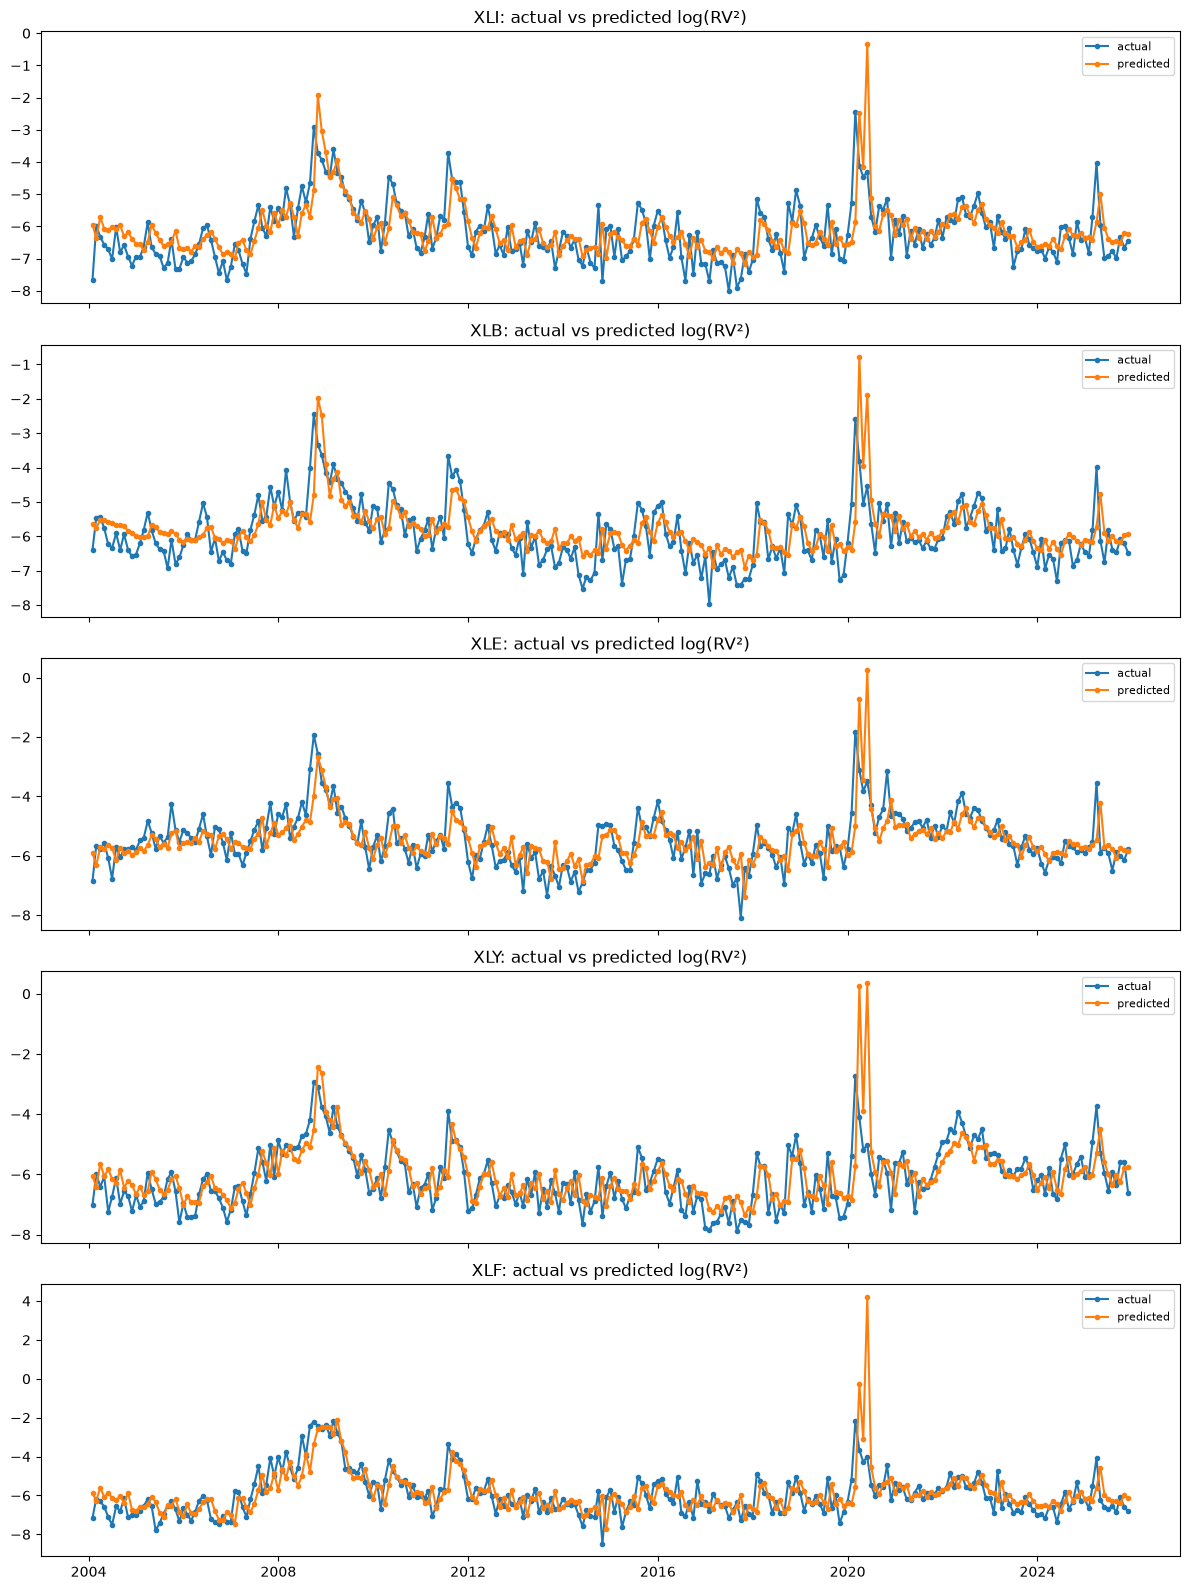

In [19]:
fig, axes = plt.subplots(5, 1, figsize=(12, 16), sharex=True)
for ax, ticker in zip(axes, CYCLICAL_TICKERS):
    df = forecasts[ticker]
    ax.plot(df.index, df["log_rv_sq_actual"], label="actual", marker="o", markersize=3)
    ax.plot(df.index, df["log_rv_sq_pred"], label="predicted", marker="o", markersize=3)
    ax.set_title(f"{ticker}: actual vs predicted log(RV\u00b2)")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

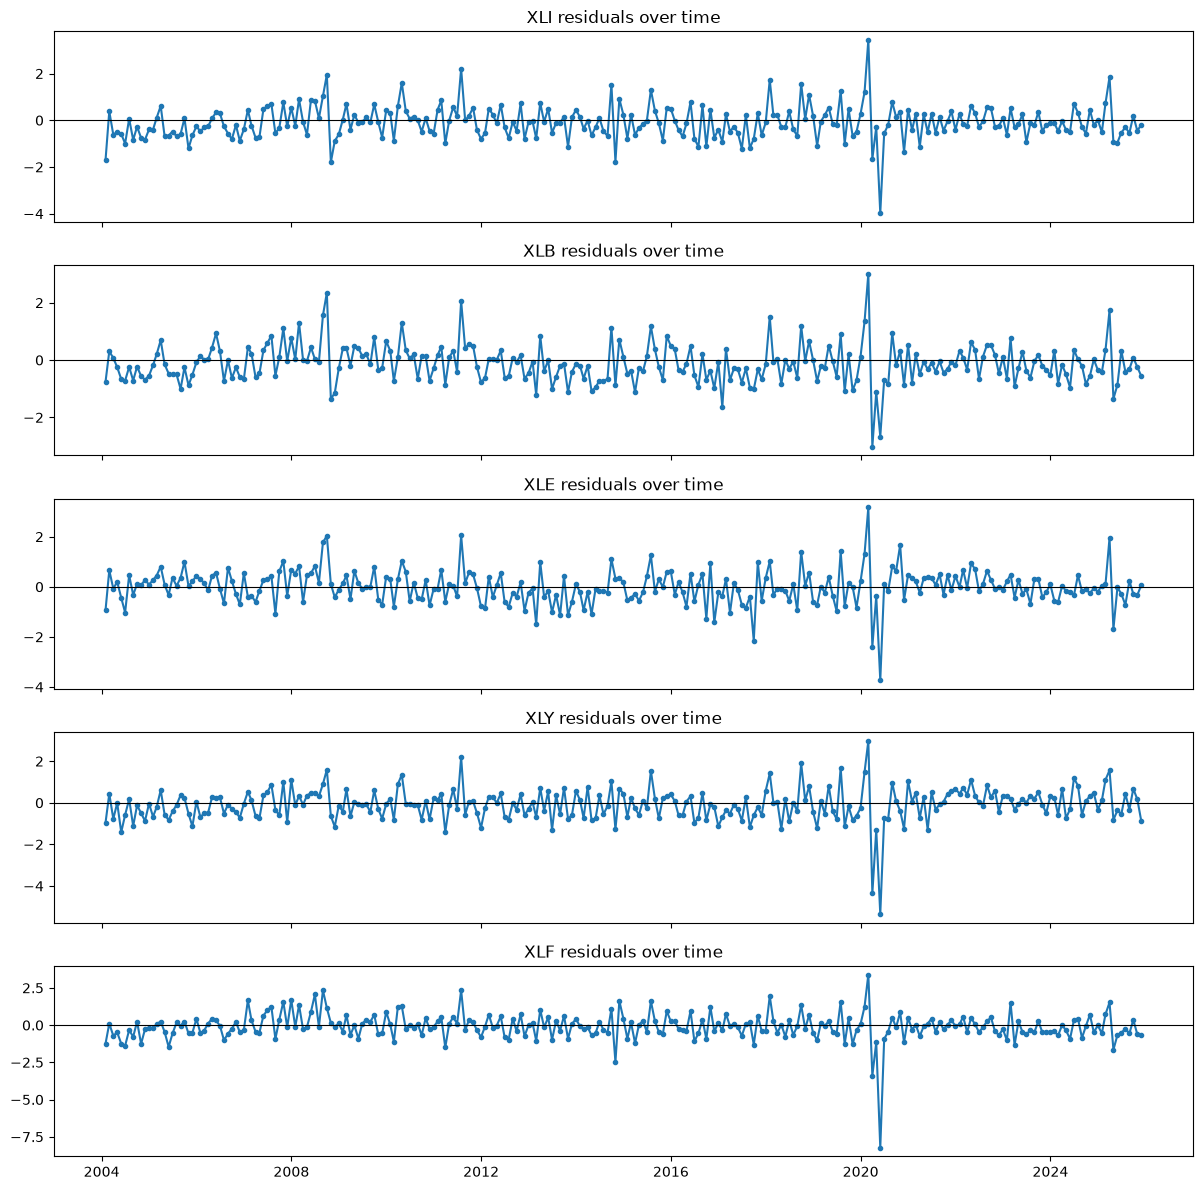

In [20]:
fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
for ax, ticker in zip(axes, CYCLICAL_TICKERS):
    df = forecasts[ticker]
    residuals = df["log_rv_sq_actual"] - df["log_rv_sq_pred"]
    ax.plot(df.index, residuals, marker="o", markersize=3)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{ticker} residuals over time")
fig.tight_layout()
plt.show()

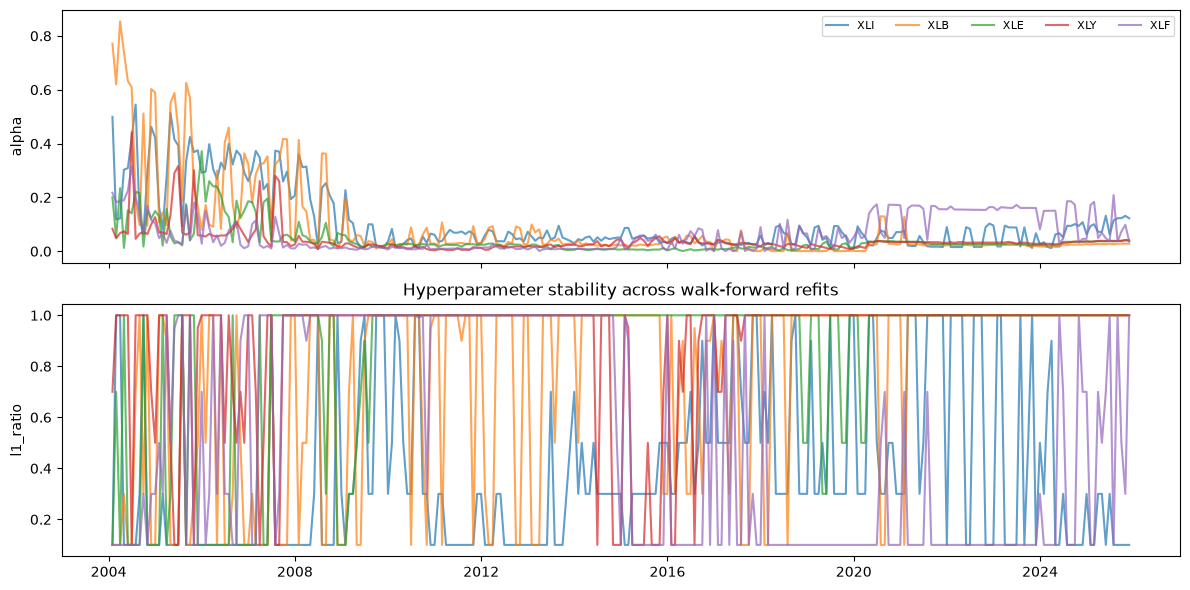

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ticker in CYCLICAL_TICKERS:
    df = forecasts[ticker]
    axes[0].plot(df.index, df["alpha"], label=ticker, alpha=0.7)
    axes[1].plot(df.index, df["l1_ratio"], label=ticker, alpha=0.7)
axes[0].set_ylabel("alpha")
axes[0].legend(fontsize=8, ncol=5)
axes[1].set_ylabel("l1_ratio")
axes[1].set_title("Hyperparameter stability across walk-forward refits")
fig.tight_layout()
plt.show()